# Graceful Degradation in Weather Agent Workflows

## Overview

In production AI agent systems, external dependencies will fail. APIs go down, rate limits hit, networks timeout. **Graceful degradation** is a workflow-level error handling pattern that keeps your agent functional by automatically falling back to alternative data sources when primary services fail.

Think of it like a restaurant: if the kitchen runs out of salmon, they offer you chicken instead. If chicken runs out too, they offer a vegetarian option. The key is **you still get a meal** - it just might not be your first choice.

## Learning Objectives

By the end of this tutorial, you will:

1. Understand graceful degradation as a workflow-level error handling pattern
2. Implement multi-level fallback pathways using LangGraph conditional edges
3. Build a weather agent with three degradation levels (API → Search → LLM)
4. Compare quality/cost/latency tradeoffs across different data sources
5. Route workflow execution dynamically based on service availability

## Prerequisites

**API Keys Required:**
- **OpenAI API Key**: For the LLM reasoning
- **OpenWeatherMap API Key**: Primary weather data source (https://openweathermap.org/api - free tier)
- **Tavily API Key**: Web search fallback (https://tavily.com - free tier)

**Required Packages:**
```bash
pip install langgraph langchain-openai langchain-core python-dotenv requests tavily-python pydantic
```

**Setup Instructions:**

1. Create a `.env` file in your project directory
2. Add your API keys:
   ```
   OPENAI_API_KEY=your-openai-key-here
   OPENWEATHER_API_KEY=your-openweather-key-here
   TAVILY_API_KEY=your-tavily-key-here
   ```

## What is Graceful Degradation?

Graceful degradation is a design philosophy where systems maintain functionality at reduced capacity when components fail, rather than failing completely.

**Traditional Error Handling:**
```
Try API → If fails, return error message ❌
```

**Graceful Degradation:**
```
Try API → If fails, try Search → If fails, use LLM knowledge ✓
```

### Quality Hierarchy

Our weather agent will have three levels:

| Level | Source | Quality | Latency | Cost | Reliability |
|-------|--------|---------|---------|------|-------------|
| 0 | OpenWeather API | Real-time, precise | ~200ms | Free | 99%+ |
| 1 | Tavily Web Search | Recent, approximate | ~1-2s | Free (limited) | 99.9%+ |
| 2 | LLM General Knowledge | Seasonal patterns | ~500ms | Tokens | 100% |

The workflow **automatically downgrades** when higher-quality sources fail.

### When to Use Graceful Degradation

**Good Use Cases:**
- Weather information (approximate is better than nothing)
- News/content aggregation (stale is better than missing)
- Recommendations (general is better than none)
- Informational queries (best-effort is acceptable)

**Bad Use Cases:**
- Financial transactions (accuracy critical)
- Medical diagnoses (precision required)
- Legal documents (exactness mandatory)
- Authentication/authorization (security critical)

**Rule of Thumb:** Use graceful degradation when **approximate/stale data is better than no data**, and the consequences of lower-quality information are acceptable.

## Part 1: Setup and Imports

Let's import all necessary libraries and load our environment variables.

In [15]:
import os
import logging
import requests
from datetime import datetime
from typing import TypedDict, Optional, List, Literal
from enum import Enum

from dotenv import load_dotenv
from pydantic import BaseModel, Field, field_validator
from tavily import TavilyClient

from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

# Load environment variables
load_dotenv()

# Verify all API keys are present
required_keys = ["OPENAI_API_KEY", "OPENWEATHER_API_KEY", "TAVILY_API_KEY"]
missing_keys = [key for key in required_keys if not os.getenv(key)]

if missing_keys:
    raise ValueError(f"Missing required API keys: {', '.join(missing_keys)}")

print("All required API keys loaded successfully!")
print("Libraries imported successfully!")

All required API keys loaded successfully!
Libraries imported successfully!


## Part 2: Configure Structured Logging

Logging is crucial for understanding degradation behavior in production. We'll log:
- Which data source is being attempted
- Why sources failed
- Which degradation level was ultimately used
- Execution time at each level

In [16]:
# Configure logging with clear format
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',
    datefmt='%H:%M:%S'
)

# Create logger for our workflow
logger = logging.getLogger('weather_workflow')

# Test the logger
logger.info("Logging system initialized")

print("Logging configured - watch for structured logs during execution")

12:54:42 - weather_workflow - INFO - Logging system initialized


Logging configured - watch for structured logs during execution


## Part 3: Build Three Weather Data Sources

We'll create three functions, each representing a different quality level. Each function returns a tuple:
- `success` (bool): Whether the data source worked
- `result` (str): The weather information or error message

This consistent interface makes it easy to chain fallbacks in our workflow.

### Level 0: OpenWeather API (Primary Source)

**Advantages:**
- Real-time data updated every 10 minutes
- Precise temperature, humidity, wind speed
- Reliable (99%+ uptime)

**Disadvantages:**
- Can fail during maintenance
- Rate limits on free tier
- Requires valid API key

In [17]:
# Reuse geocoding helper from the application-specific tools notebook
def geocode_city(city_name: str) -> tuple[float, float]:
    """
    Convert city name to latitude/longitude using OpenWeatherMap Geocoding API.
    
    Args:
        city_name: Name of the city to geocode
    
    Returns:
        Tuple of (latitude, longitude)
    
    Raises:
        ValueError: If city not found or API request fails
    """
    city_name = city_name.strip()
    
    if not city_name:
        raise ValueError("City name cannot be empty")
    
    api_key = os.getenv("OPENWEATHER_API_KEY")
    url = "http://api.openweathermap.org/geo/1.0/direct"
    
    params = {
        "q": city_name,
        "limit": 1,
        "appid": api_key
    }
    
    try:
        response = requests.get(url, params=params, timeout=5)
        response.raise_for_status()
        data = response.json()
        
        if not data:
            raise ValueError(f"City '{city_name}' not found")
        
        return data[0]["lat"], data[0]["lon"]
        
    except requests.exceptions.RequestException as e:
        raise ValueError(f"Geocoding failed: {str(e)}")


def get_weather_from_api(city: str) -> tuple[bool, str]:
    """
    Get real-time weather from OpenWeatherMap API.
    
    This is Level 0 - the highest quality data source.
    
    Args:
        city: City name to query
    
    Returns:
        Tuple of (success, result_string)
    """
    logger.info(f"[Level 0] Attempting OpenWeather API for {city}")
    
    try:
        # Geocode the city
        lat, lon = geocode_city(city)
        
        # Get current weather
        api_key = os.getenv("OPENWEATHER_API_KEY")
        url = "https://api.openweathermap.org/data/2.5/weather"
        
        params = {
            "lat": lat,
            "lon": lon,
            "units": "metric",
            "appid": api_key
        }
        
        response = requests.get(url, params=params, timeout=5)
        response.raise_for_status()
        
        data = response.json()
        
        # Format detailed weather information
        temp = data['main']['temp']
        feels_like = data['main']['feels_like']
        description = data['weather'][0]['description']
        humidity = data['main']['humidity']
        wind_speed = data['wind']['speed']
        
        result = (
            f"Real-time weather in {city}:\n"
            f"  Temperature: {temp}°C (feels like {feels_like}°C)\n"
            f"  Conditions: {description.capitalize()}\n"
            f"  Humidity: {humidity}%\n"
            f"  Wind Speed: {wind_speed} m/s\n"
            f"  Data Quality: Real-time API data (most accurate)"
        )
        
        logger.info(f"[Level 0] SUCCESS - API returned real-time data")
        return True, result
        
    except Exception as e:
        error_msg = f"API failed: {str(e)}"
        logger.warning(f"[Level 0] FAILED - {error_msg}")
        return False, error_msg


# Test the API function
print("Testing OpenWeather API...")
success, result = get_weather_from_api("London")
if success:
    print(f"\n{result}")
else:
    print(f"\nFailed: {result}")

12:54:42 - weather_workflow - INFO - [Level 0] Attempting OpenWeather API for London
12:54:42 - weather_workflow - INFO - [Level 0] SUCCESS - API returned real-time data


Testing OpenWeather API...

Real-time weather in London:
  Temperature: 13.21°C (feels like 13.07°C)
  Conditions: Light rain
  Humidity: 95%
  Wind Speed: 5.14 m/s
  Data Quality: Real-time API data (most accurate)


### Level 1: Web Search Fallback (Tavily)

**Advantages:**
- Works when API is down
- Still provides recent weather information
- More reliable than direct API (99.9%+ uptime)

**Disadvantages:**
- Less precise (scraped from web sources)
- Slower (1-2 second latency)
- May include outdated information

In [18]:
def get_weather_from_search(city: str) -> tuple[bool, str]:
    """
    Get weather information from web search results.
    
    This is Level 1 - fallback when API fails.
    
    Args:
        city: City name to query
    
    Returns:
        Tuple of (success, result_string)
    """
    logger.info(f"[Level 1] Attempting Tavily web search for {city}")
    
    try:
        # Initialize Tavily client
        tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
        
        # Search for current weather
        query = f"current weather in {city} today temperature"
        search_results = tavily_client.search(
            query=query,
            max_results=3,
            search_depth="basic"
        )
        
        if not search_results or 'results' not in search_results:
            raise ValueError("No search results found")
        
        # Extract weather information from search results
        # Combine snippets from top results
        weather_info = []
        for result in search_results['results'][:2]:
            if 'content' in result:
                weather_info.append(result['content'][:200])
        
        if not weather_info:
            raise ValueError("No weather content extracted from search")
        
        combined_info = " ".join(weather_info)
        
        result = (
            f"Web-sourced weather for {city}:\n"
            f"  {combined_info[:300]}...\n\n"
            f"  Data Quality: Recent web information (approximate)"
        )
        
        logger.info(f"[Level 1] SUCCESS - Search returned weather information")
        return True, result
        
    except Exception as e:
        error_msg = f"Search failed: {str(e)}"
        logger.warning(f"[Level 1] FAILED - {error_msg}")
        return False, error_msg


# Test the search function
print("Testing Tavily web search...")
success, result = get_weather_from_search("Paris")
if success:
    print(f"\n{result}")
else:
    print(f"\nFailed: {result}")

12:54:42 - weather_workflow - INFO - [Level 1] Attempting Tavily web search for Paris


Testing Tavily web search...


12:54:44 - weather_workflow - INFO - [Level 1] SUCCESS - Search returned weather information



Web-sourced weather for Paris:
  {'location': {'name': 'Paris', 'region': 'Ile-de-France', 'country': 'France', 'lat': 48.8667, 'lon': 2.3333, 'tz_id': 'Europe/Paris', 'localtime_epoch': 1763096086, 'localtime': '2025-11-14 05:54'},  During November, expect a variety of temperatures with highs around 11° and lows near 6°, suitable ...

  Data Quality: Recent web information (approximate)


### Level 2: LLM General Knowledge (Last Resort)

**Advantages:**
- Always works (100% availability)
- No external dependencies
- Provides seasonal/typical patterns

**Disadvantages:**
- Not real-time (knowledge cutoff)
- Generic information only
- Cannot provide actual current conditions

In [19]:
# Initialize LLM for fallback
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.3)


def get_weather_from_llm(city: str) -> tuple[bool, str]:
    """
    Get general weather information from LLM's knowledge.
    
    This is Level 2 - last resort when both API and search fail.
    
    Args:
        city: City name to query
    
    Returns:
        Tuple of (success, result_string)
    """
    logger.info(f"[Level 2] Using LLM general knowledge for {city}")
    
    try:
        # Determine current season
        month = datetime.now().month
        if month in [12, 1, 2]:
            season = "winter"
        elif month in [3, 4, 5]:
            season = "spring"
        elif month in [6, 7, 8]:
            season = "summer"
        else:
            season = "autumn"
        
        # Ask LLM for typical weather patterns
        prompt = (
            f"What is the typical weather in {city} during {season}? "
            f"Provide a brief description including typical temperature range, "
            f"common conditions, and what to expect. Keep it under 100 words. "
            f"Be clear that this is general seasonal information, not current conditions."
        )
        
        response = llm.invoke(prompt)
        llm_content = response.content
        
        result = (
            f"General weather patterns for {city} ({season}):\n"
            f"  {llm_content}\n\n"
            f"  Data Quality: Seasonal patterns from LLM knowledge (not real-time)"
        )
        
        logger.info(f"[Level 2] SUCCESS - LLM provided general weather information")
        return True, result
        
    except Exception as e:
        # LLM should rarely fail, but handle it gracefully
        error_msg = f"LLM failed: {str(e)}"
        logger.error(f"[Level 2] FAILED - {error_msg}")
        return False, error_msg


# Test the LLM function
print("Testing LLM general knowledge...")
success, result = get_weather_from_llm("Tokyo")
if success:
    print(f"\n{result}")
else:
    print(f"\nFailed: {result}")

12:54:44 - weather_workflow - INFO - [Level 2] Using LLM general knowledge for Tokyo


Testing LLM general knowledge...


12:54:48 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
12:54:48 - weather_workflow - INFO - [Level 2] SUCCESS - LLM provided general weather information



General weather patterns for Tokyo (autumn):
  During autumn in Tokyo, typically from September to November, temperatures range from 15°C to 25°C (59°F to 77°F). September can still be warm and humid, while October and November bring cooler, crisp air. Expect mostly clear skies with occasional rain, especially in September. The vibrant fall foliage, particularly in parks and gardens, adds to the beauty of the season. Overall, autumn is a pleasant time to visit, with comfortable weather and stunning natural scenery.

  Data Quality: Seasonal patterns from LLM knowledge (not real-time)


## Part 4: Define LangGraph State Schema

Our state needs to track:
1. **User's query** (city name)
2. **Current degradation level** (0, 1, or 2)
3. **Final result** (weather information)
4. **Error log** (what went wrong at each level)
5. **Data quality indicator** (for user transparency)

This rich state allows us to:
- Make routing decisions based on failures
- Track which fallbacks were used
- Provide transparency to users about data quality

In [20]:
class WeatherWorkflowState(TypedDict):
    """State for weather workflow with graceful degradation."""
    city: str                          # User's city query
    degradation_level: int             # 0=API, 1=Search, 2=LLM
    result: Optional[str]              # Final weather information
    error_log: List[str]               # Track what failed at each level
    data_quality: str                  # "high", "medium", "low"


print("State schema defined!")
print("\nState fields:")
print("  - city: The city to get weather for")
print("  - degradation_level: Which data source we're currently trying (0-2)")
print("  - result: The weather information (set when successful)")
print("  - error_log: List of errors encountered during fallbacks")
print("  - data_quality: Quality indicator (high/medium/low)")

State schema defined!

State fields:
  - city: The city to get weather for
  - degradation_level: Which data source we're currently trying (0-2)
  - result: The weather information (set when successful)
  - error_log: List of errors encountered during fallbacks
  - data_quality: Quality indicator (high/medium/low)


## Part 5: Build Workflow Nodes

Each node attempts one data source and updates the state accordingly.

**Node Responsibilities:**
1. Log what it's attempting
2. Try its designated data source
3. If successful: populate `result` and `data_quality`
4. If failed: add error to `error_log`
5. Return updated state for routing decision

**Special Note on `format_response_node`:**
This node uses an LLM to generate a natural, conversational response that:
- Synthesizes the weather data in a user-friendly way
- Explains the data quality level transparently
- Acknowledges any degradation that occurred (with context)
- Maintains a positive, helpful tone

This creates a much better user experience compared to raw data dumps!

In [21]:
def parse_request_node(state: WeatherWorkflowState) -> WeatherWorkflowState:
    """
    Entry node: Validate input and initialize state.
    """
    logger.info(f"=== Starting weather query for: {state['city']} ===")
    
    return {
        "city": state["city"],
        "degradation_level": 0,  # Start at highest quality level
        "result": None,
        "error_log": [],
        "data_quality": "high"
    }


def try_api_node(state: WeatherWorkflowState) -> WeatherWorkflowState:
    """
    Level 0: Attempt to get weather from OpenWeather API.
    """
    success, result = get_weather_from_api(state["city"])
    
    if success:
        return {
            "city": state["city"],
            "degradation_level": 0,
            "result": result,
            "error_log": state["error_log"],
            "data_quality": "high"
        }
    else:
        # Failed - prepare for fallback
        error_log = state["error_log"] + [f"Level 0 (API): {result}"]
        return {
            "city": state["city"],
            "degradation_level": 1,  # Move to next level
            "result": None,
            "error_log": error_log,
            "data_quality": state["data_quality"]
        }


def try_search_node(state: WeatherWorkflowState) -> WeatherWorkflowState:
    """
    Level 1: Attempt to get weather from web search.
    """
    success, result = get_weather_from_search(state["city"])
    
    if success:
        return {
            "city": state["city"],
            "degradation_level": 1,
            "result": result,
            "error_log": state["error_log"],
            "data_quality": "medium"
        }
    else:
        # Failed - prepare for final fallback
        error_log = state["error_log"] + [f"Level 1 (Search): {result}"]
        return {
            "city": state["city"],
            "degradation_level": 2,  # Move to final level
            "result": None,
            "error_log": error_log,
            "data_quality": state["data_quality"]
        }


def try_llm_node(state: WeatherWorkflowState) -> WeatherWorkflowState:
    """
    Level 2: Get weather from LLM general knowledge (last resort).
    """
    success, result = get_weather_from_llm(state["city"])
    
    if success:
        return {
            "city": state["city"],
            "degradation_level": 2,
            "result": result,
            "error_log": state["error_log"],
            "data_quality": "low"
        }
    else:
        # Complete failure (rare)
        error_log = state["error_log"] + [f"Level 2 (LLM): {result}"]
        return {
            "city": state["city"],
            "degradation_level": 2,
            "result": f"Unable to retrieve weather for {state['city']}. All data sources failed.",
            "error_log": error_log,
            "data_quality": "none"
        }


def format_response_node(state: WeatherWorkflowState) -> WeatherWorkflowState:
    """
    Final node: Use LLM to generate a natural, conversational response that
    synthesizes weather data with degradation context.
    """
    logger.info("[Formatter] Generating natural language response with LLM")

    raw_weather_data = state["result"]
    degradation_level = state["degradation_level"]
    error_log = state["error_log"]
    data_quality = state["data_quality"]
    city = state["city"]

    # Map quality levels to user-friendly descriptions
    quality_descriptions = {
        "high": "real-time API data (most accurate and current)",
        "medium": "recent web search results (approximate but recent)",
        "low": "general seasonal patterns from knowledge base (not real-time)",
        "none": "no data available"
    }

    quality_desc = quality_descriptions.get(data_quality, "unknown quality")

    # Build context for LLM
    if error_log:
        # Degradation occurred - explain what happened
        error_context = f"\n\nImportant context: We encountered {len(error_log)} errors while trying to get weather data:\n"
        for i, error in enumerate(error_log, 1):
            error_context += f"{i}. {error}\n"
        error_context += f"\nWe successfully fell back to degradation level {degradation_level} to provide you with information."
    else:
        error_context = "\n\nWe successfully retrieved data from our primary source (no fallbacks needed)."

    # Create prompt for LLM
    prompt = f"""You are a helpful weather assistant. Generate a natural, conversational response for the user about the weather in {city}.

Here's the weather information we gathered:
{raw_weather_data}

Data quality level: {quality_desc}
{error_context}

Your task:
1. Present the weather information in a clear, friendly way
2. Be transparent about the data quality (mention it's {quality_desc})
3. If degradation occurred (errors exist), briefly acknowledge it but stay positive
4. Keep the response concise (2-3 paragraphs max)
5. Don't use emojis in the main text, but include a quality badge at the end

Quality badges to use:
- High quality: 🟢 Real-time Data
- Medium quality: 🟡 Web Search Data  
- Low quality: 🔴 General Patterns

Format your response naturally, as if talking to a user. End with the appropriate quality badge."""

    try:
        # Generate response with LLM
        llm_response = llm.invoke(prompt)
        formatted_result = llm_response.content

        logger.info("[Formatter] Successfully generated natural language response")

    except Exception as e:
        # Fallback if LLM fails (shouldn't happen, but be safe)
        logger.error(f"[Formatter] LLM formatting failed: {e}")

        # Fallback to simple formatting
        quality_badge = {
            "high": "🟢 High Quality",
            "medium": "🟡 Medium Quality",
            "low": "🔴 Low Quality",
            "none": "❌ No Data"
        }.get(data_quality, "Unknown")

        formatted_result = f"{raw_weather_data}\n\nData Quality: {quality_badge}"
        if error_log:
            formatted_result += f"\n\n⚠️  Note: Fell back to level {degradation_level} after {len(error_log)} errors."

    logger.info(f"=== Query completed at degradation level {degradation_level} ===")

    return {
        "city": state["city"],
        "degradation_level": state["degradation_level"],
        "result": formatted_result,
        "error_log": state["error_log"],
        "data_quality": state["data_quality"]
    }


print("All workflow nodes defined!")
print("\nNode summary:")
print("  1. parse_request: Validate input and initialize state")
print("  2. try_api: Attempt Level 0 (OpenWeather API)")
print("  3. try_search: Attempt Level 1 (Tavily search)")
print("  4. try_llm: Attempt Level 2 (LLM knowledge)")
print("  5. format_response: Use LLM to generate natural conversational response")

All workflow nodes defined!

Node summary:
  1. parse_request: Validate input and initialize state
  2. try_api: Attempt Level 0 (OpenWeather API)
  3. try_search: Attempt Level 1 (Tavily search)
  4. try_llm: Attempt Level 2 (LLM knowledge)
  5. format_response: Use LLM to generate natural conversational response


## Part 6: Build Routing Functions

These functions examine the state and decide where to route next:

- If data source succeeded (`result` is not None) → Go to format_response
- If data source failed (`result` is None) → Try next fallback level

This is the **heart of graceful degradation** - the conditional routing that automatically moves down the quality hierarchy when failures occur.

In [22]:
def route_after_api(state: WeatherWorkflowState) -> Literal["format_response", "try_search"]:
    """
    Route after API attempt:
    - If API succeeded → format_response
    - If API failed → try_search
    """
    if state["result"] is not None:
        logger.info("[Router] API succeeded, routing to format_response")
        return "format_response"
    else:
        logger.info("[Router] API failed, routing to try_search")
        return "try_search"


def route_after_search(state: WeatherWorkflowState) -> Literal["format_response", "try_llm"]:
    """
    Route after search attempt:
    - If search succeeded → format_response
    - If search failed → try_llm
    """
    if state["result"] is not None:
        logger.info("[Router] Search succeeded, routing to format_response")
        return "format_response"
    else:
        logger.info("[Router] Search failed, routing to try_llm")
        return "try_llm"


print("Routing functions defined!")
print("\nRouting logic:")
print("  - After API: Success → format | Failure → search")
print("  - After Search: Success → format | Failure → LLM")
print("  - After LLM: Always → format (last resort)")

Routing functions defined!

Routing logic:
  - After API: Success → format | Failure → search
  - After Search: Success → format | Failure → LLM
  - After LLM: Always → format (last resort)


## Part 7: Construct LangGraph Workflow

Now we assemble all the pieces into a complete workflow graph.

**Key Features:**
1. Linear entry: START → parse_request → try_api
2. Conditional branching after each attempt (success vs. failure)
3. Three degradation levels with automatic fallback
4. All paths converge at format_response → END

This structure ensures that **no matter what fails**, we always return something to the user.

In [23]:
# Create the state graph
workflow = StateGraph(WeatherWorkflowState)

# Add all nodes
workflow.add_node("parse_request", parse_request_node)
workflow.add_node("try_api", try_api_node)
workflow.add_node("try_search", try_search_node)
workflow.add_node("try_llm", try_llm_node)
workflow.add_node("format_response", format_response_node)

# Add edges
workflow.add_edge(START, "parse_request")
workflow.add_edge("parse_request", "try_api")

# Conditional edges for graceful degradation
workflow.add_conditional_edges(
    "try_api",
    route_after_api,
    {
        "format_response": "format_response",
        "try_search": "try_search"
    }
)

workflow.add_conditional_edges(
    "try_search",
    route_after_search,
    {
        "format_response": "format_response",
        "try_llm": "try_llm"
    }
)

# LLM always goes to format (last resort)
workflow.add_edge("try_llm", "format_response")
workflow.add_edge("format_response", END)

# Compile the workflow
weather_app = workflow.compile()

print("Workflow compiled successfully!")
print("\nWorkflow structure:")
print("  START → parse_request → try_api")
print("                            ├─ [success] → format_response → END")
print("                            └─ [failure] → try_search")
print("                                            ├─ [success] → format_response → END")
print("                                            └─ [failure] → try_llm → format_response → END")

Workflow compiled successfully!

Workflow structure:
  START → parse_request → try_api
                            ├─ [success] → format_response → END
                            └─ [failure] → try_search
                                            ├─ [success] → format_response → END
                                            └─ [failure] → try_llm → format_response → END


### Visualize the Workflow

Let's create a visual representation of our graceful degradation workflow.

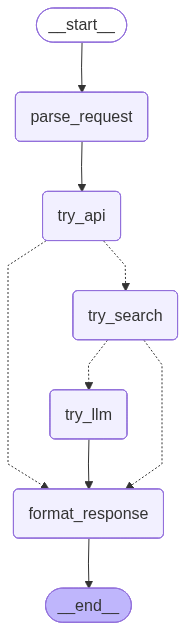

In [24]:
from IPython.display import Image, display

try:
    display(Image(weather_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Could not generate graph visualization: {e}")
    print("\nWorkflow structure (text):")
    print("""
    START
      ↓
    parse_request
      ↓
    try_api (Level 0: OpenWeather API)
      ├─→ [SUCCESS] → format_response → END
      └─→ [FAILURE] → try_search (Level 1: Tavily Search)
                        ├─→ [SUCCESS] → format_response → END
                        └─→ [FAILURE] → try_llm (Level 2: LLM Knowledge)
                                          ↓
                                      format_response
                                          ↓
                                        END
    """)

## Part 8: Test Scenario 1 - Normal Operation (Level 0)

**Expected Behavior:**
- API should work normally
- Should return detailed real-time data
- Data quality: High (green badge)
- No fallbacks triggered

This is the **happy path** - what happens when everything works correctly.

In [25]:
print("=" * 80)
print("TEST SCENARIO 1: Normal Operation - API Success")
print("=" * 80)
print("\nExpected: Level 0 (API) should succeed with high-quality real-time data\n")

initial_state = {
    "city": "London",
    "degradation_level": 0,
    "result": None,
    "error_log": [],
    "data_quality": "high"
}

result = weather_app.invoke(initial_state)

print("\n" + "=" * 80)
print("FINAL RESULT:")
print("=" * 80)
print(f"\n{result['result']}")
print(f"\nDegradation level used: {result['degradation_level']}")
print(f"Errors encountered: {len(result['error_log'])}")

12:54:48 - weather_workflow - INFO - === Starting weather query for: London ===
12:54:48 - weather_workflow - INFO - [Level 0] Attempting OpenWeather API for London
12:54:48 - weather_workflow - INFO - [Level 0] SUCCESS - API returned real-time data
12:54:48 - weather_workflow - INFO - [Router] API succeeded, routing to format_response
12:54:48 - weather_workflow - INFO - [Formatter] Generating natural language response with LLM


TEST SCENARIO 1: Normal Operation - API Success

Expected: Level 0 (API) should succeed with high-quality real-time data



12:54:53 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
12:54:53 - weather_workflow - INFO - [Formatter] Successfully generated natural language response
12:54:53 - weather_workflow - INFO - === Query completed at degradation level 0 ===



FINAL RESULT:

Currently, the weather in London is a bit damp, with light rain falling and a temperature of around 13.2°C, which feels slightly cooler at 13.1°C. The humidity is quite high at 95%, so it might feel a bit muggy out there. There's a gentle breeze blowing at about 5.1 m/s, which could provide a little relief from the rain.

This information is pulled from real-time API data, ensuring it's the most accurate and current available. So, if you're heading out, it might be a good idea to grab an umbrella! 

🟢 Real-time Data

Degradation level used: 0
Errors encountered: 0


## Part 9: Test Scenario 2 - API Failure (Level 1 Degradation)

**Simulating API Failure:**
We'll temporarily break the API by using an invalid API key, forcing the workflow to fall back to web search.

**Expected Behavior:**
- API should fail (invalid credentials)
- Workflow automatically routes to search
- Search should succeed with web-scraped data
- Data quality: Medium (yellow badge)
- User sees degradation warning

This demonstrates **automatic fallback in action**.

In [26]:
print("=" * 80)
print("TEST SCENARIO 2: API Failure - Search Fallback")
print("=" * 80)
print("\nSimulating API failure by temporarily using invalid credentials...\n")

# Save original API key
original_api_key = os.getenv("OPENWEATHER_API_KEY")

# Temporarily set invalid API key
os.environ["OPENWEATHER_API_KEY"] = "invalid_key_for_testing"

try:
    initial_state = {
        "city": "London",
        "degradation_level": 0,
        "result": None,
        "error_log": [],
        "data_quality": "high"
    }
    
    result = weather_app.invoke(initial_state)
    
    print("\n" + "=" * 80)
    print("FINAL RESULT:")
    print("=" * 80)
    print(f"\n{result['result']}")
    print(f"\nDegradation level used: {result['degradation_level']}")
    print(f"Errors encountered: {len(result['error_log'])}")
    
    if result['error_log']:
        print("\nError details:")
        for i, error in enumerate(result['error_log'], 1):
            print(f"  {i}. {error}")
    
finally:
    # Restore original API key
    os.environ["OPENWEATHER_API_KEY"] = original_api_key
    print("\n[API key restored]")

12:54:53 - weather_workflow - INFO - === Starting weather query for: London ===
12:54:53 - weather_workflow - INFO - [Level 0] Attempting OpenWeather API for London
12:54:53 - weather_workflow - WARNING - [Level 0] FAILED - API failed: Geocoding failed: 401 Client Error: Unauthorized for url: http://api.openweathermap.org/geo/1.0/direct?q=London&limit=1&appid=invalid_key_for_testing
12:54:53 - weather_workflow - INFO - [Router] API failed, routing to try_search
12:54:53 - weather_workflow - INFO - [Level 1] Attempting Tavily web search for London


TEST SCENARIO 2: API Failure - Search Fallback

Simulating API failure by temporarily using invalid credentials...



12:54:56 - weather_workflow - INFO - [Level 1] SUCCESS - Search returned weather information
12:54:56 - weather_workflow - INFO - [Router] Search succeeded, routing to format_response
12:54:56 - weather_workflow - INFO - [Formatter] Generating natural language response with LLM
12:55:01 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
12:55:01 - weather_workflow - INFO - [Formatter] Successfully generated natural language response
12:55:01 - weather_workflow - INFO - === Query completed at degradation level 1 ===



FINAL RESULT:

Hey there! The weather in London right now is quite chilly, typical for November. You can expect temperatures to range between 42°F and 51°F, so it’s a good idea to bundle up if you’re heading out. It might feel a bit brisk, especially with the potential for some wind.

I gathered this information from recent web sources, so while it's approximate, it should give you a decent idea of what to expect. We did encounter a minor issue retrieving the most precise data, but overall, it looks like a typical London autumn day. Stay warm out there! 🟡 Web Search Data

Degradation level used: 1
Errors encountered: 1

Error details:
  1. Level 0 (API): API failed: Geocoding failed: 401 Client Error: Unauthorized for url: http://api.openweathermap.org/geo/1.0/direct?q=London&limit=1&appid=invalid_key_for_testing

[API key restored]


## Part 10: Test Scenario 3 - API + Search Failure (Level 2 Degradation)

**Simulating Double Failure:**
We'll break both the API and search to force the workflow down to LLM general knowledge.

**Expected Behavior:**
- API fails (invalid credentials)
- Search fails (invalid API key)
- Workflow falls back to LLM
- LLM provides seasonal/typical weather patterns
- Data quality: Low (red badge)
- User sees multiple degradation warnings

This demonstrates the **full degradation chain** - all the way to the last resort.

In [27]:
print("=" * 80)
print("TEST SCENARIO 3: Double Failure - LLM Fallback")
print("=" * 80)
print("\nSimulating both API and Search failures...\n")

# Save original API keys
original_weather_key = os.getenv("OPENWEATHER_API_KEY")
original_tavily_key = os.getenv("TAVILY_API_KEY")

# Temporarily set invalid API keys
os.environ["OPENWEATHER_API_KEY"] = "invalid_weather_key"
os.environ["TAVILY_API_KEY"] = "invalid_tavily_key"

try:
    initial_state = {
        "city": "London",
        "degradation_level": 0,
        "result": None,
        "error_log": [],
        "data_quality": "high"
    }
    
    result = weather_app.invoke(initial_state)
    
    print("\n" + "=" * 80)
    print("FINAL RESULT:")
    print("=" * 80)
    print(f"\n{result['result']}")
    print(f"\nDegradation level used: {result['degradation_level']}")
    print(f"Errors encountered: {len(result['error_log'])}")
    
    if result['error_log']:
        print("\nError details:")
        for i, error in enumerate(result['error_log'], 1):
            print(f"  {i}. {error}")
    
finally:
    # Restore original API keys
    os.environ["OPENWEATHER_API_KEY"] = original_weather_key
    os.environ["TAVILY_API_KEY"] = original_tavily_key
    print("\n[API keys restored]")

12:55:01 - weather_workflow - INFO - === Starting weather query for: London ===
12:55:01 - weather_workflow - INFO - [Level 0] Attempting OpenWeather API for London
12:55:01 - weather_workflow - WARNING - [Level 0] FAILED - API failed: Geocoding failed: 401 Client Error: Unauthorized for url: http://api.openweathermap.org/geo/1.0/direct?q=London&limit=1&appid=invalid_weather_key
12:55:01 - weather_workflow - INFO - [Router] API failed, routing to try_search
12:55:01 - weather_workflow - INFO - [Level 1] Attempting Tavily web search for London


TEST SCENARIO 3: Double Failure - LLM Fallback

Simulating both API and Search failures...



12:55:02 - weather_workflow - WARNING - [Level 1] FAILED - Search failed: Invalid API key: Unauthorized: missing or invalid API key.
12:55:02 - weather_workflow - INFO - [Router] Search failed, routing to try_llm
12:55:02 - weather_workflow - INFO - [Level 2] Using LLM general knowledge for London
12:55:05 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
12:55:05 - weather_workflow - INFO - [Level 2] SUCCESS - LLM provided general weather information
12:55:05 - weather_workflow - INFO - [Formatter] Generating natural language response with LLM
12:55:11 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
12:55:11 - weather_workflow - INFO - [Formatter] Successfully generated natural language response
12:55:11 - weather_workflow - INFO - === Query completed at degradation level 2 ===



FINAL RESULT:

The weather in London during autumn, which runs from September to November, typically sees temperatures ranging from 10°C to 18°C (50°F to 64°F). Early in the season, you might still enjoy some mild days, but as autumn progresses, it does get cooler. You'll experience a mix of sunny spells and overcast skies, with November bringing more frequent rainfall. The beautiful fall foliage adds a lovely touch to the city's parks and streets, making it a charming time to explore.

Just a heads up, the information I provided is based on general seasonal patterns rather than real-time data, as we encountered some issues retrieving the latest weather updates. So, it's always a good idea to dress in layers and keep an umbrella handy, as the weather can be quite unpredictable. Enjoy your time in London!

🔴 General Patterns

Degradation level used: 2
Errors encountered: 2

Error details:
  1. Level 0 (API): API failed: Geocoding failed: 401 Client Error: Unauthorized for url: http://a